In [1]:
import torch 

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [8]:
x = torch.linspace(-2, 2, 50).unsqueeze(1)

In [4]:
x

tensor([[-2.0000],
        [-1.9664],
        [-1.9328],
        [-1.8992],
        [-1.8655],
        [-1.8319],
        [-1.7983],
        [-1.7647],
        [-1.7311],
        [-1.6975],
        [-1.6639],
        [-1.6303],
        [-1.5966],
        [-1.5630],
        [-1.5294],
        [-1.4958],
        [-1.4622],
        [-1.4286],
        [-1.3950],
        [-1.3613],
        [-1.3277],
        [-1.2941],
        [-1.2605],
        [-1.2269],
        [-1.1933],
        [-1.1597],
        [-1.1261],
        [-1.0924],
        [-1.0588],
        [-1.0252],
        [-0.9916],
        [-0.9580],
        [-0.9244],
        [-0.8908],
        [-0.8571],
        [-0.8235],
        [-0.7899],
        [-0.7563],
        [-0.7227],
        [-0.6891],
        [-0.6555],
        [-0.6218],
        [-0.5882],
        [-0.5546],
        [-0.5210],
        [-0.4874],
        [-0.4538],
        [-0.4202],
        [-0.3866],
        [-0.3529],
        [-0.3193],
        [-0.2857],
        [-0.

In [13]:
noise = 0.6 * torch.randn_like(x)
y = 3 * x + 2 + noise

In [10]:
import matplotlib.pyplot as plt

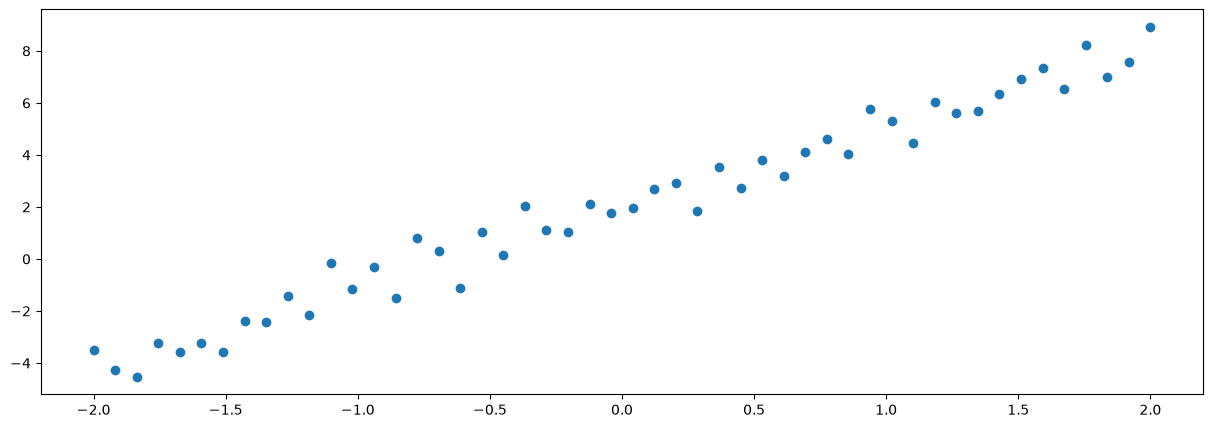

In [14]:
plt.figure(figsize=(15,5))
plt.scatter(x,y)

In [15]:
import torch.nn as nn 

In [16]:
model = nn.Linear(1,1)

In [25]:
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
losses = []
for epoch in range(500):
    y_pred = model(x)
    loss = loss_function(y_pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 100 ==0 : 
        print(f"epoch={epoch} loss={loss.item():.4f}")

epoch=0 loss=0.3733
epoch=100 loss=0.3685
epoch=200 loss=0.3685
epoch=300 loss=0.3685
epoch=400 loss=0.3685


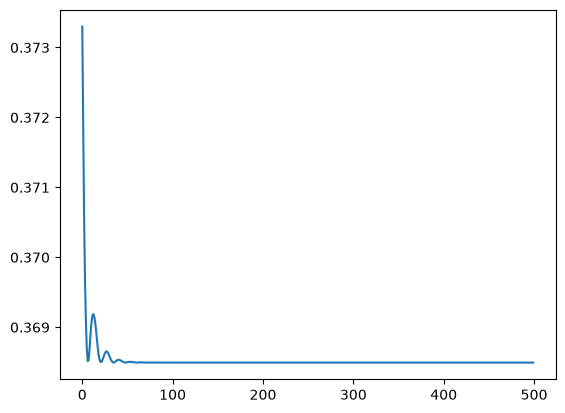

In [26]:
plt.plot(losses)

In [20]:
with torch.inference_mode():
    pred= model(x)

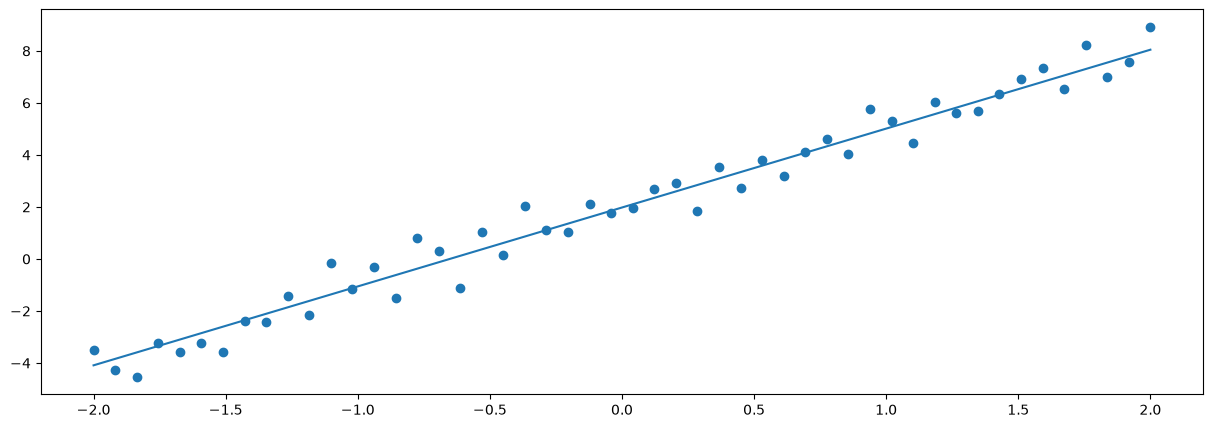

In [22]:
plt.figure(figsize=(15,5))
plt.scatter(x,y)
plt.plot(x,pred)

In [23]:
from torcheval.metrics import R2Score  

In [24]:
r2score = R2Score()
r2score.update(y,pred)
r2=r2score.compute()
print(f"R2 Score = {r2:.3f}")

R2 Score = 0.971


## Partie 2

#### Exercice 1

In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Nombre de salariés
n = 300

# Ancienneté : de 0 à 20 ans
anciennete = torch.randint(0, 21, (n, 1)).float()

# Expertise : de 1 à 5
expertise = torch.randint(1, 6, (n, 1)).float()

# Variations aléatoires des salaires
bruit = torch.randn(n, 1) * 500

# Salaire mensuel en DH
salaires = (
    4000
    + 600 * anciennete
    + 1500 * expertise
    + bruit
)

# Matrice des entrées : dimensions (300, 2)
X = torch.cat([anciennete, expertise], dim=1)

# Sortie : dimensions (300, 1)
y = salaires

for i in range(5):
    print(
        f"Ancienneté : {X[i, 0].item():.0f} ans | "
        f"Expertise : {X[i, 1].item():.0f}/5 | "
        f"Salaire : {y[i, 0].item():.2f} DH"
    )

Ancienneté : 15 ans | Expertise : 2/5 | Salaire : 16262.90 DH
Ancienneté : 2 ans | Expertise : 3/5 | Salaire : 10541.39 DH
Ancienneté : 4 ans | Expertise : 3/5 | Salaire : 10948.37 DH
Ancienneté : 19 ans | Expertise : 3/5 | Salaire : 20028.54 DH
Ancienneté : 18 ans | Expertise : 2/5 | Salaire : 18036.38 DH
